# Computational Linear Algebra: PCA Homework

## Exercise 0.0: Initialization
Fill the missing values in this text box. **Remove the information of the second student if you are not working in a team**.

**Academic Year:** 2025/2026

### Team Members (Alphabetical Order):
1. R, A (S000000);

Now, fill the python list below with the Student IDs of the team

In [1]:
StudentIDs = [000000]

## Exercise 0.1: Starting Code-Cell 

Download the .csv files from the web page of the course (*responses_hw.csv* and *columns_hw.csv*) and past them in **the same folder of this notebook**.


Then, run the cell below, **without modifing any line of code**.

The output of this code cell is **your personal subset of the original dataset**, with 2/3 of the original features (i.e., columns) and 3/4 of the original persons (i.e., rows).

### ATTENTION: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL, ANY CHANGE CAN INVALIDATE THE HOMEWORK!

In [2]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Finances
Shopping centres
Branded clothing
Entertainment spending
Spending on looks
Spending on gadgets
Spending on healthy eating
Alcohol
Healthy eating
History
Psychology
Internet
Economy Management
Chemistry
Reading
Foreign languages
Law
Art exhibitions
Religion
Dancing
Writing
Passive sport
Celebrities
Shopping
Science and technology
Fun with friends
Pets
Movies
Horror
Thriller
Romantic
Sci-fi
War
Fantasy/Fairy tales
Animated
Western
Action
Slow songs or fast songs
Dance
Folk
Country
Musical
Punk
Hiphop, Rap
Swing, Jazz
Alternative
Techno, Trance
Opera
Daily events
Prioritising workload
Writing notes
Workaholism
Thinking ahead
Final judgement
Loss of interest
Friends versus money
Funniness
Fake
Decision making
Self-criticism
Hypochondria
Giving
Compassion to animals
Borrowed stuff
Cheating in school
Health
Changing the past
God
Charity
Number of friends
Punctuality
Waiting
New environment
Appearence and gestures
Social

,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on gadgets,Spending on healthy eating,Alcohol,Healthy eating,History,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
180,3,5,1,4,3,1,4,social drinker,3,2,...,19,164,60,2,female,right,secondary school,no,village,house/bungalow
233,3,3,5,5,3,2,5,social drinker,3,4,...,19,175,58,0,female,right,college/bachelor degree,yes,city,block of flats
443,3,2,2,4,4,3,4,never,3,2,...,23,158,64,3,female,right,masters degree,no,city,block of flats
589,4,4,4,3,3,2,4,never,4,2,...,25,168,63,1,female,right,masters degree,no,city,house/bungalow
468,4,5,4,3,4,3,4,social drinker,4,5,...,18,174,64,1,male,right,secondary school,no,city,house/bungalow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,5,4,4,3,4,5,4,social drinker,3,3,...,20,168,69,1,female,right,secondary school,no,village,house/bungalow
390,3,3,2,4,3,2,2,social drinker,2,1,...,20,173,55,1,female,right,secondary school,yes,village,house/bungalow
324,4,4,4,4,4,2,4,social drinker,5,3,...,20,165,65,1,male,right,college/bachelor degree,no,village,house/bungalow
145,3,1,1,2,2,2,2,drink a lot,3,1,...,24,169,51,1,female,right,college/bachelor degree,no,city,house/bungalow



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on gadgets,Spending on healthy eating,Alcohol,Healthy eating,History,...,Energy levels,Personality,Interests or hobbies,Parents' advice,Questionnaires or polls,Internet usage,Flying,Storm,Snakes,Dangerous dogs
180,3,5,1,4,3,1,4,social drinker,3,2,...,5,3,3,3,3,few hours a day,3,3,3,5
233,3,3,5,5,3,2,5,social drinker,3,4,...,4,3,3,4,2,few hours a day,2,4,1,3
443,3,2,2,4,4,3,4,never,3,2,...,5,3,4,3,3,few hours a day,3,4,4,5
589,4,4,4,3,3,2,4,never,4,2,...,5,3,4,3,3,few hours a day,5,2,4,2
468,4,5,4,3,4,3,4,social drinker,4,5,...,3,4,4,3,5,few hours a day,2,1,4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,5,4,4,3,4,5,4,social drinker,3,3,...,3,3,2,4,3,few hours a day,2,2,4,5
390,3,3,2,4,3,2,2,social drinker,2,1,...,4,3,3,3,3,most of the day,1,3,5,4
324,4,4,4,4,4,2,4,social drinker,5,3,...,4,3,5,4,4,less than an hour a day,1,1,3,3
145,3,1,1,2,2,2,2,drink a lot,3,1,...,2,3,2,3,2,few hours a day,2,1,3,3



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
180,19,164,60,2,female,right,secondary school,no,village,house/bungalow
233,19,175,58,0,female,right,college/bachelor degree,yes,city,block of flats
443,23,158,64,3,female,right,masters degree,no,city,block of flats
589,25,168,63,1,female,right,masters degree,no,city,house/bungalow
468,18,174,64,1,male,right,secondary school,no,city,house/bungalow
...,...,...,...,...,...,...,...,...,...,...
152,20,168,69,1,female,right,secondary school,no,village,house/bungalow
390,20,173,55,1,female,right,secondary school,yes,village,house/bungalow
324,20,165,65,1,male,right,college/bachelor degree,no,village,house/bungalow
145,24,169,51,1,female,right,college/bachelor degree,no,city,house/bungalow


## Exercise 0.2: Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.

For reproducibility, **no extra modules are allowed**.

**DO NOT IMPORT NUMPY NOR PANDAS**, they are already imported.

In [3]:
# Plotting
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm

# Preprocessing
from sklearn.preprocessing import StandardScaler

# PCA
from sklearn.decomposition import PCA

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

## Exercise 1. Dataset Preprocessing

In this exercise, you have to do the following operations on the dataset of the features **responses_ft**:
1. Create a new dataframe called **responses_ft_enc** by encoding the categorical features (if they exist), motivating your choices;
1. Create a new dataframe called **responses_ft_pp** by preprocessing the data in **responses_ft_enc**, according to the scaler reported in the cell below.

In [4]:
print(f'*** YOU HAVE TO APPLY A PREPROCESSING USING THE {your_scaler}')

*** YOU HAVE TO APPLY A PREPROCESSING USING THE StandardScaler


For doing this exercise, fill the cells below following the instructions you read.

#### Describe and motivate the encoding operations you will apply (max 150 words):

Based on my Student ID, my personal dataset contains 3 categorical features: Alcohol, Punctuality, and Internet usage. According to the project documentation (Appendix A), these variables have a natural order from low to high, making them ordinal. Therefore, I apply ordinal encoding by mapping each category to an integer that preserves this order: Alcohol (never=1, social drinker=2, drink a lot=3), Punctuality (early=1, on time=2, late=3), and Internet usage (no time at all=1, less than an hour a day=2, few hours a day=3, most of the day=4). This encoding step is crucial because PCA requires all input features to be numeric.

#### Describe the preprocessing operation you will apply and comment the effects it may have on the data (max 150 words):

Based on my Student ID, StandardScaler was assigned for preprocessing. Other scaling techniques exist, such as MinMaxScaler, but StandardScaler transforms each feature to have mean=0 and standard deviation=1 using the formula z = (x - μ) / σ. Although most features in this dataset are already on a similar 1-5 scale, standardization remains important for PCA. Standardization guarantees a fair comparison across all features. By centering all features at zero and normalizing their spread, we ensure that each feature contributes equally to the variance analysis. Without standardization, features with slightly higher variance could disproportionately influence the principal components, even if the scale differences are small. 

#### Write the code for performing the encoding and preprocessing operations of the exercise. Show the encoded data and the preprocessed data you obtain, plus any additional table/value that can be useful for commenting the results:

In [5]:
# ============================================
# STEP 1: ENCODING CATEGORICAL FEATURES
# ============================================

# Start with a copy of the original features
responses_ft_enc = responses_ft.copy()

# Show categorical columns BEFORE encoding
print("BEFORE ENCODING:")
display(responses_ft[['Alcohol', 'Punctuality', 'Internet usage']].head(5))

# Define the ordinal mappings (ordered from low to high)
alcohol_map = {
    'never': 1,
    'social drinker': 2,
    'drink a lot': 3
}

punctuality_map = {
    'early': 1,
    'on time': 2,
    'late': 3
}

internet_map = {
    'no time at all': 1,
    'less than an hour a day': 2,
    'few hours a day': 3,
    'most of the day': 4
}

# Apply the mappings
responses_ft_enc['Alcohol'] = responses_ft_enc['Alcohol'].map(alcohol_map)
responses_ft_enc['Punctuality'] = responses_ft_enc['Punctuality'].map(punctuality_map)
responses_ft_enc['Internet usage'] = responses_ft_enc['Internet usage'].map(internet_map)

# Show categorical columns AFTER encoding
print("\nAFTER ENCODING:")
display(responses_ft_enc[['Alcohol', 'Punctuality', 'Internet usage']].head(5))

# ============================================
# STEP 2: PREPROCESSING WITH STANDARDSCALER
# ============================================

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the data
responses_ft_pp_values = scaler.fit_transform(responses_ft_enc) # the outpur is a NumPy array without columns name

# Convert back to DataFrame - to have names and index
responses_ft_pp = pd.DataFrame(
    responses_ft_pp_values,
    columns=responses_ft_enc.columns,
    index=responses_ft_enc.index
)

# Show sample of data BEFORE and AFTER scaling
print("\nBEFORE SCALING:")
display(responses_ft_enc.iloc[:5, :6])

print("\nAFTER SCALING:")
display(responses_ft_pp.iloc[:5, :6]) 

BEFORE ENCODING:


,Alcohol,Punctuality,Internet usage
180,social drinker,on time,few hours a day
233,social drinker,late,few hours a day
443,never,early,few hours a day
589,never,early,few hours a day
468,social drinker,on time,few hours a day



AFTER ENCODING:


,Alcohol,Punctuality,Internet usage
180,2,2,3
233,2,3,3
443,1,1,3
589,1,1,3
468,2,2,3



BEFORE SCALING:


,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on gadgets
180,3,5,1,4,3,1
233,3,3,5,5,3,2
443,3,2,2,4,4,3
589,4,4,4,3,3,2
468,4,5,4,3,4,3



AFTER SCALING:


,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on gadgets
180,-0.063190,1.338014,-1.596685,0.679371,-0.096706,-1.433914
233,-0.063190,-0.225577,1.510710,1.517813,-0.096706,-0.659570
443,-0.063190,-1.007373,-0.819837,0.679371,0.761773,0.114774
589,0.824983,0.556218,0.733861,-0.159072,-0.096706,-0.659570
468,0.824983,1.338014,0.733861,-0.159072,0.761773,0.114774


#### Comment the results obtained after the preprocessing operation (max 100 words):

After applying StandardScaler, all features now have mean ≈ 0 and standard deviation ≈ 1. The standardization ensures all features are on the same scale and centered at zero. This is essential for PCA because it prevents features with larger values from dominating the principal components.

## Exercise 2. Analyzing the Variance and the PCs

In this exercise, you have to do the following operations:
1. compute and visualize the variance of all the features in *responses_ft_enc* and *responses_ft_pp*;
1. compute all the $n$ Principal Components (PCs) for *responses_ft_enc* and *responses_ft_pp*, separately, and visualize the curves of the cumulative explained variances.

For doing this exercise, fill the cells below following the instructions you read.

#### Write the code for computing and visualizing the variance of the features of the two datasets:

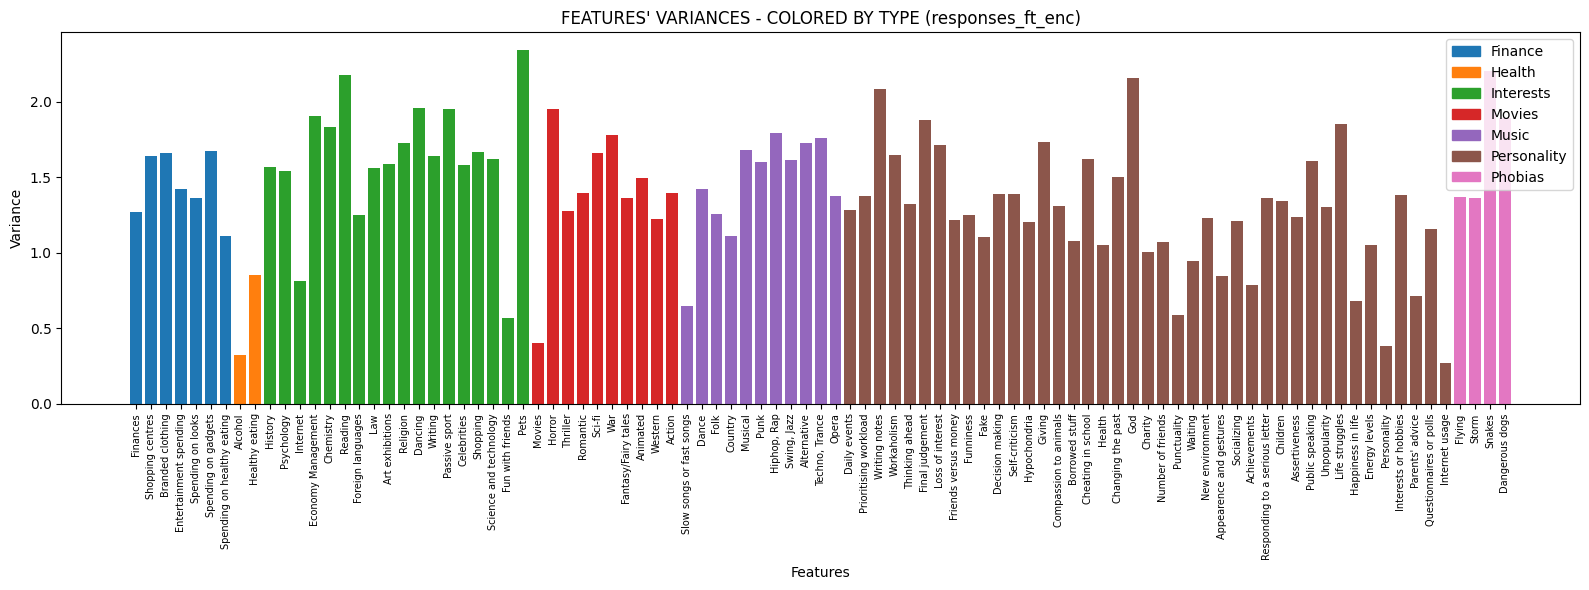

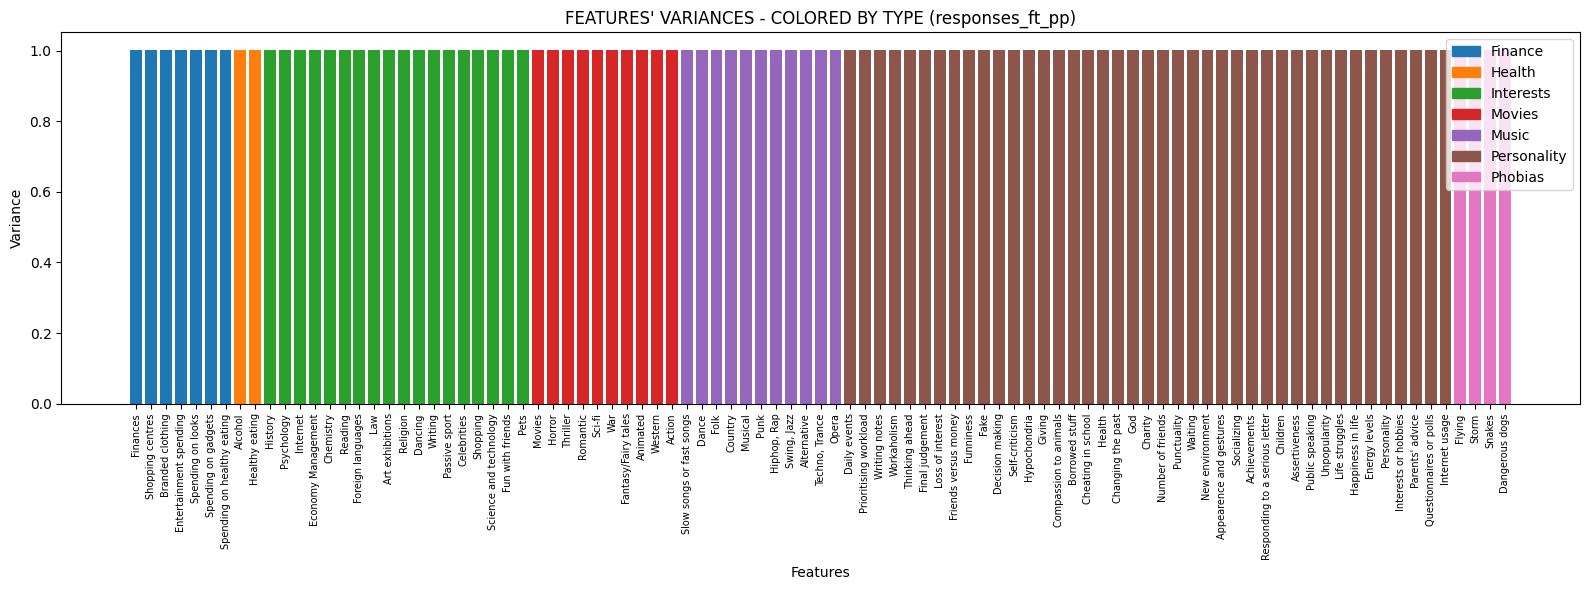

In [6]:
# Compute variance for both datasets
variance_enc = responses_ft_enc.var()
variance_pp = responses_ft_pp.var()

# --------------------------------------------
# Create color mapping for each feature by type
# --------------------------------------------

# Define colors for each category
colors_by_type = {
    'Finance': 'tab:blue',
    'Health': 'tab:orange',
    'Interests': 'tab:green',
    'Movies': 'tab:red',
    'Music': 'tab:purple',
    'Personality': 'tab:brown',
    'Phobias': 'tab:pink'
}

# Create a list of colors for each feature (in order)
feature_colors = []
for feature in responses_ft_enc.columns:
    for ftype, flist in features_by_type.items():
        if feature in flist:
            feature_colors.append(colors_by_type[ftype])
            break

# --------------------------------------------
# Plot 1: Variance of responses_ft_enc
# --------------------------------------------

fig, ax = plt.subplots(figsize=(16, 6))
bars = ax.bar(range(len(variance_enc)), variance_enc.values, color=feature_colors)
ax.set_xticks(range(len(variance_enc)))
ax.set_xticklabels(variance_enc.index, rotation=90, fontsize=7)
ax.set_xlabel('Features')
ax.set_ylabel('Variance')
ax.set_title("FEATURES' VARIANCES - COLORED BY TYPE (responses_ft_enc)")

# Add legend
legend_handles = [plt.Rectangle((0,0),1,1, color=colors_by_type[t]) for t in colors_by_type]
ax.legend(legend_handles, colors_by_type.keys(), loc='upper right')

plt.tight_layout()
plt.show()

# --------------------------------------------
# Plot 2: Variance of responses_ft_pp
# --------------------------------------------

fig, ax = plt.subplots(figsize=(16, 6))
bars = ax.bar(range(len(variance_pp)), variance_pp.values, color=feature_colors)
ax.set_xticks(range(len(variance_pp)))
ax.set_xticklabels(variance_pp.index, rotation=90, fontsize=7)
ax.set_xlabel('Features')
ax.set_ylabel('Variance')
ax.set_title("FEATURES' VARIANCES - COLORED BY TYPE (responses_ft_pp)")

# Add legend
ax.legend(legend_handles, colors_by_type.keys(), loc='upper right')

plt.tight_layout()
plt.show()

#### Comment the results obtained for the variances (max 150 words):

The two bar plots clearly demonstrate the effect of StandardScaler preprocessing. In the first plot (responses_ft_enc), features show varying variance levels, typically ranging from approximately 0.5 to 2.0, depending on their original scale and how respondents answered. Some features have higher variance (more diverse responses) while others have lower variance (more consistent responses). The colors show that variance differences exist across all categories - Finance, Health, Interests, Movies, Music, Personality, and Phobias - with no single category dominating. In the second plot (responses_ft_pp), after applying StandardScaler, all features have exactly the same variance of approximately 1.0, represented by uniform bar heights. This confirms that standardization successfully normalized all features to have equal variance, which is essential for PCA to treat each feature with equal importance.

#### Write the code for computing all the $n$ PCs of the two datasets, separately, and for visualizing the curves of cumulative explained variances:

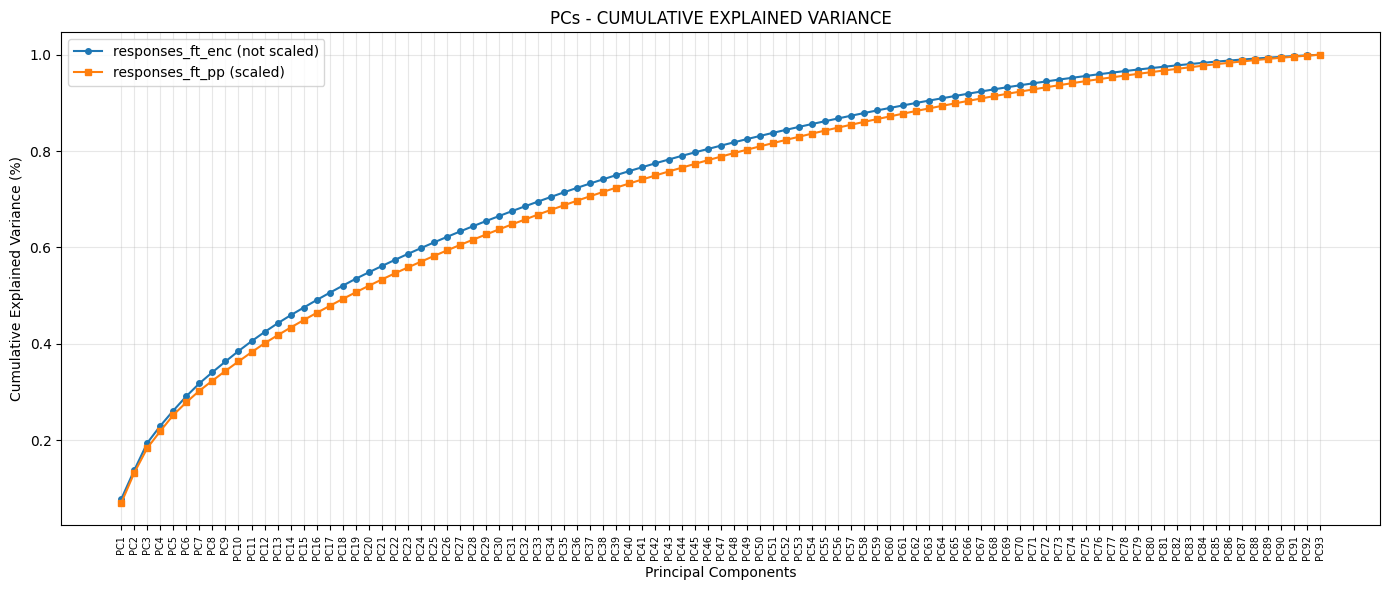


*** CUMULATIVE EXPLAINED VARIANCE (responses_ft_enc):
PC1: 0.0775 (7.75%)
PC2: 0.1376 (13.76%)
PC3: 0.1941 (19.41%)

*** CUMULATIVE EXPLAINED VARIANCE (responses_ft_pp):
PC1: 0.0694 (6.94%)
PC2: 0.1321 (13.21%)
PC3: 0.1836 (18.36%)


In [7]:
# PCA on encoded data (NOT scaled)
pca_enc = PCA()
pca_enc.fit(responses_ft_enc)

# PCA on preprocessed data (scaled)
pca_pp = PCA()
pca_pp.fit(responses_ft_pp)

# Compute cumulative explained variance
cumvar_enc = np.cumsum(pca_enc.explained_variance_ratio_)
cumvar_pp = np.cumsum(pca_pp.explained_variance_ratio_)

# Number of components
n_components = len(cumvar_enc)
pc_labels = [f'PC{i+1}' for i in range(n_components)]

# --------------------------------------------
# Plot: Cumulative Explained Variance
# --------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(range(1, n_components+1), cumvar_enc, 'o-', label='responses_ft_enc (not scaled)', markersize=4)
ax.plot(range(1, n_components+1), cumvar_pp, 's-', label='responses_ft_pp (scaled)', markersize=4)

ax.set_xticks(range(1, n_components+1))
ax.set_xticklabels(pc_labels, rotation=90, fontsize=7)
ax.set_xlabel('Principal Components')
ax.set_ylabel('Cumulative Explained Variance (%)')
ax.set_title('PCs - CUMULATIVE EXPLAINED VARIANCE')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print some key values
print(f"\n*** CUMULATIVE EXPLAINED VARIANCE (responses_ft_enc):")
print(f"PC1: {cumvar_enc[0]:.4f} ({cumvar_enc[0]*100:.2f}%)")
print(f"PC2: {cumvar_enc[1]:.4f} ({cumvar_enc[1]*100:.2f}%)")
print(f"PC3: {cumvar_enc[2]:.4f} ({cumvar_enc[2]*100:.2f}%)")

print(f"\n*** CUMULATIVE EXPLAINED VARIANCE (responses_ft_pp):")
print(f"PC1: {cumvar_pp[0]:.4f} ({cumvar_pp[0]*100:.2f}%)")
print(f"PC2: {cumvar_pp[1]:.4f} ({cumvar_pp[1]*100:.2f}%)")
print(f"PC3: {cumvar_pp[2]:.4f} ({cumvar_pp[2]*100:.2f}%)")

#### Comment the results obtained for the cumulative explained variances, knowing the vaues in the datasets and the fetures' variances (max 150 words):

The cumulative explained variance curves show similar behavior for both datasets, with the non-scaled version (responses_ft_enc) slightly above the scaled version (responses_ft_pp). This similarity is expected because most features in this survey dataset are already on a comparable 1-5 scale. The first three PCs explain only about 18-19% of the total variance, indicating that the data is highly dimensional with no single dominant pattern.

## Exercise 3. Dimensionality Reduction and PC Interpretation

In this exercise, you have to do the following operations:
1. For the dataset *responses_ft_pp*, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
1. Visualize as a barplot the explained variance (as percentage) for each PC, and report the preserved explained variance (as percentage) by the $m$ PCs.
1. Visualize all the PCs as barplots and give an interpretation and a name to them, **motivating your choices**.
1. Transform the *responses_ft_pp* data into their $m$-dimensional representation via PCA. Store the transformed data in the variable *responses_ft_pca*;
1. Visualize the the score graph. If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs (given at the previous step) on the axes** for better understanding the results.

#### Write the code for computing the new PCA, for visualizing the $m$ PCs as barplots:

In [8]:
# ============================================
# STEP 1: FIND m'
# ============================================

# Find m' = first PC where cumulative variance >= 0.33
m_prime = np.argmax(cumvar_pp >= 0.33) + 1

# Calculate m = min(m', 5)
m = min(m_prime, 5)

# Print results
print(f"*** To capture >= 33% of variance, we need {m_prime} PCs")
print(f"*** Cumulative variance at PC{m_prime}: {cumvar_pp[m_prime-1]*100:.2f}%")

# ============================================
# STEP 2: NEW PCA WITH m COMPONENTS
# ============================================

# Get explained variance
pca_m = PCA(n_components=m)
pca_m.fit(responses_ft_pp)
explained_var = pca_m.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

print(f"----------------------------------------------")
print(f"*** Total explained variance by {m} PCs: {cumulative_var[-1]*100:.2f}%")

*** To capture >= 33% of variance, we need 9 PCs
*** Cumulative variance at PC9: 34.38%
----------------------------------------------
*** Total explained variance by 5 PCs: 25.23%


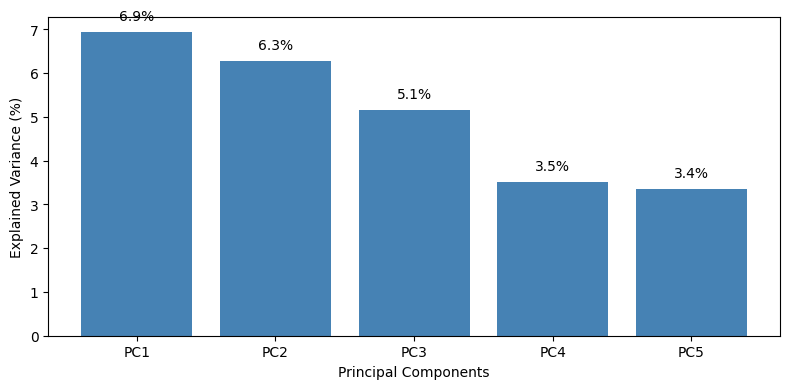

In [9]:
# ============================================
# STEP 3: BARPLOT OF EXPLAINED VARIANCE
# ============================================

fig, ax = plt.subplots(figsize=(8, 4))

pc_labels = [f'PC{i+1}' for i in range(m)]
bars = ax.bar(pc_labels, explained_var * 100, color='steelblue')

ax.set_xlabel('Principal Components')
ax.set_ylabel('Explained Variance (%)')

# Add percentage labels on top of each bar
for bar, val in zip(bars, explained_var * 100):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, 
            f'{val:.1f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

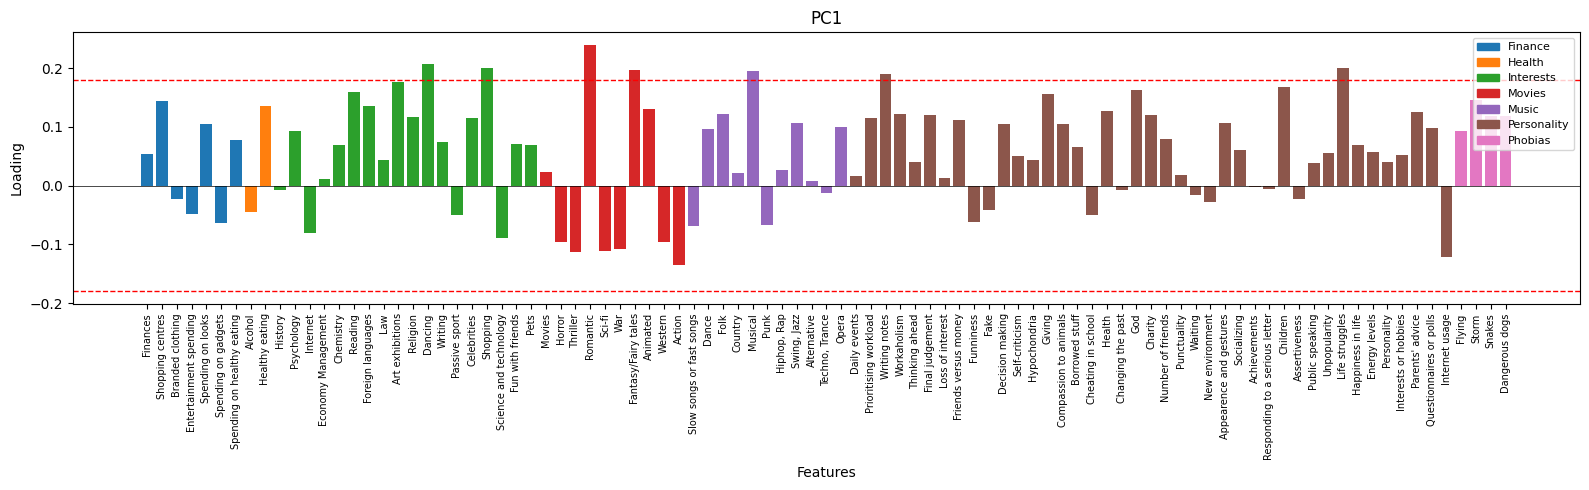

****************** PC1 **********************
HIGH-VALUED POSITIVE COMPONENTS: ['Dancing', 'Shopping', 'Romantic', 'Fantasy/Fairy tales', 'Musical', 'Writing notes', 'Life struggles']

HIGH-VALUED NEGATIVE COMPONENTS: []
*********************************************



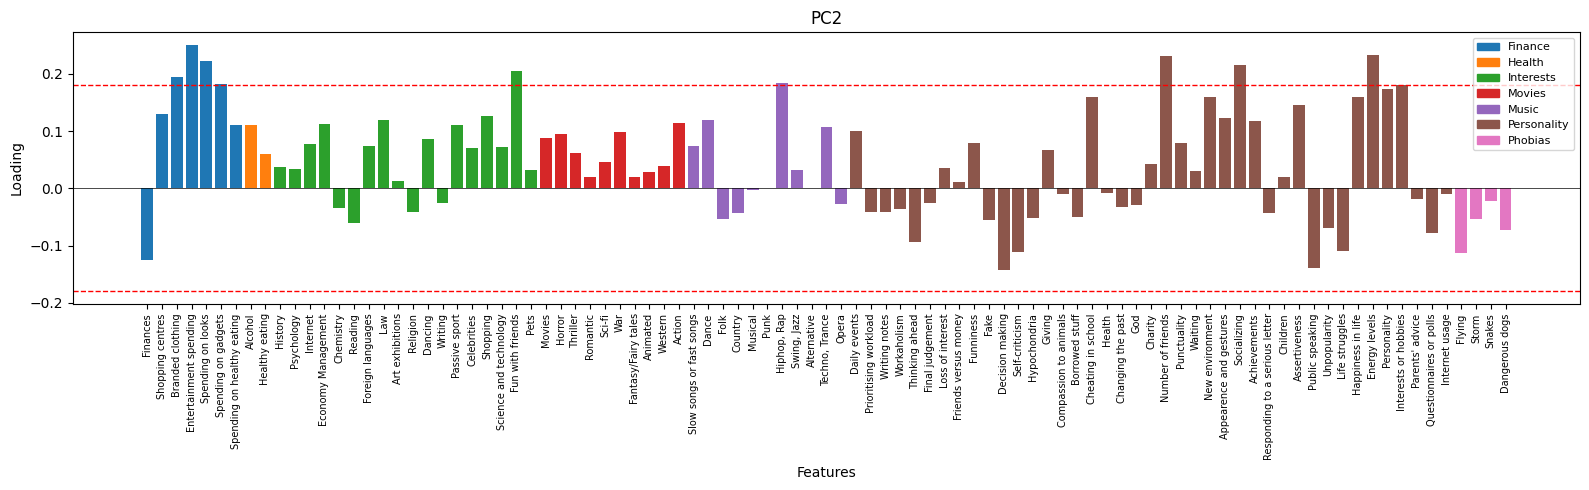

****************** PC2 **********************
HIGH-VALUED POSITIVE COMPONENTS: ['Branded clothing', 'Entertainment spending', 'Spending on looks', 'Spending on gadgets', 'Fun with friends', 'Hiphop, Rap', 'Number of friends', 'Socializing', 'Energy levels', 'Interests or hobbies']

HIGH-VALUED NEGATIVE COMPONENTS: []
*********************************************



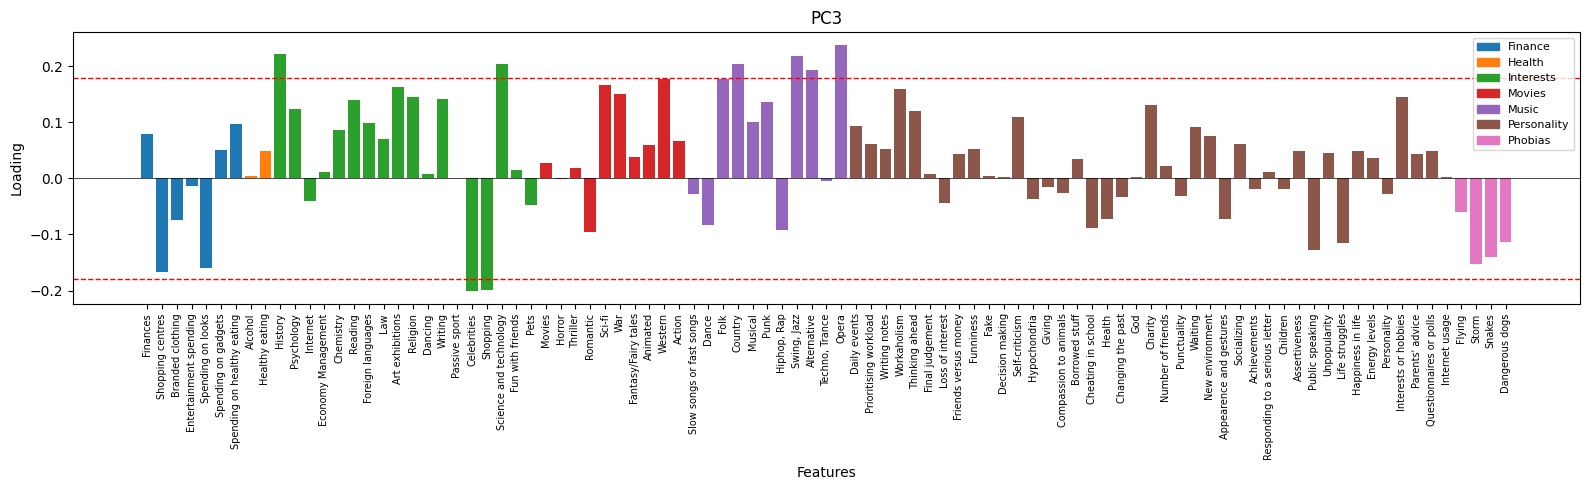

****************** PC3 **********************
HIGH-VALUED POSITIVE COMPONENTS: ['History', 'Science and technology', 'Country', 'Swing, Jazz', 'Alternative', 'Opera']

HIGH-VALUED NEGATIVE COMPONENTS: ['Celebrities', 'Shopping']
*********************************************



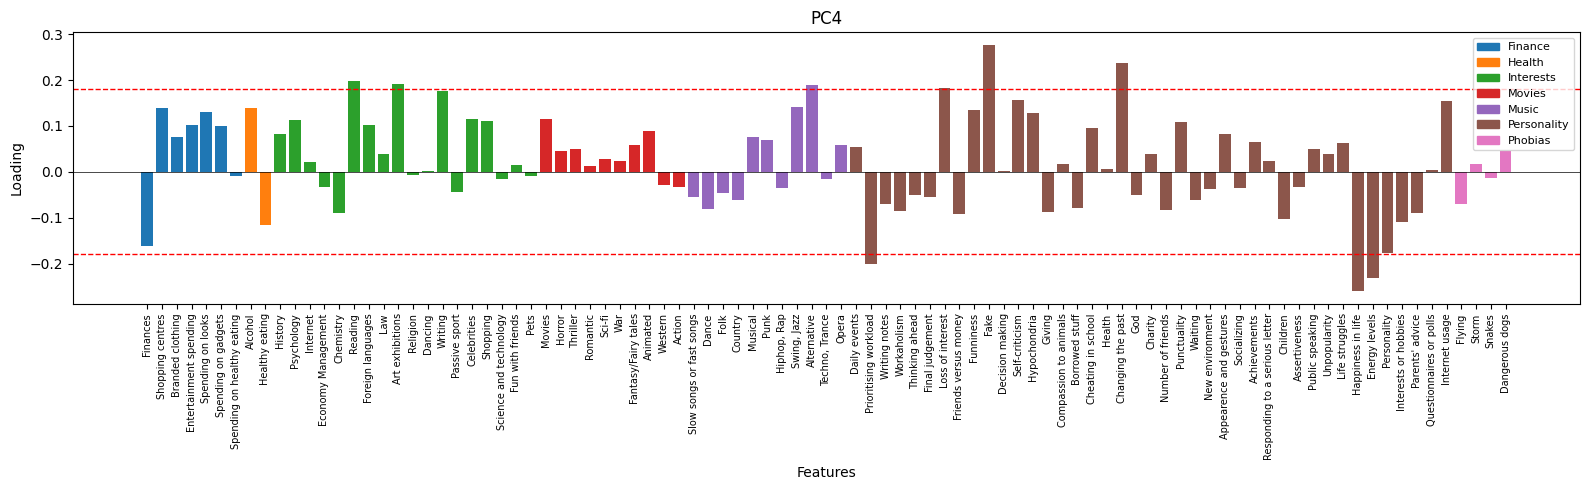

****************** PC4 **********************
HIGH-VALUED POSITIVE COMPONENTS: ['Reading', 'Art exhibitions', 'Alternative', 'Loss of interest', 'Fake', 'Changing the past']

HIGH-VALUED NEGATIVE COMPONENTS: ['Prioritising workload', 'Happiness in life', 'Energy levels']
*********************************************



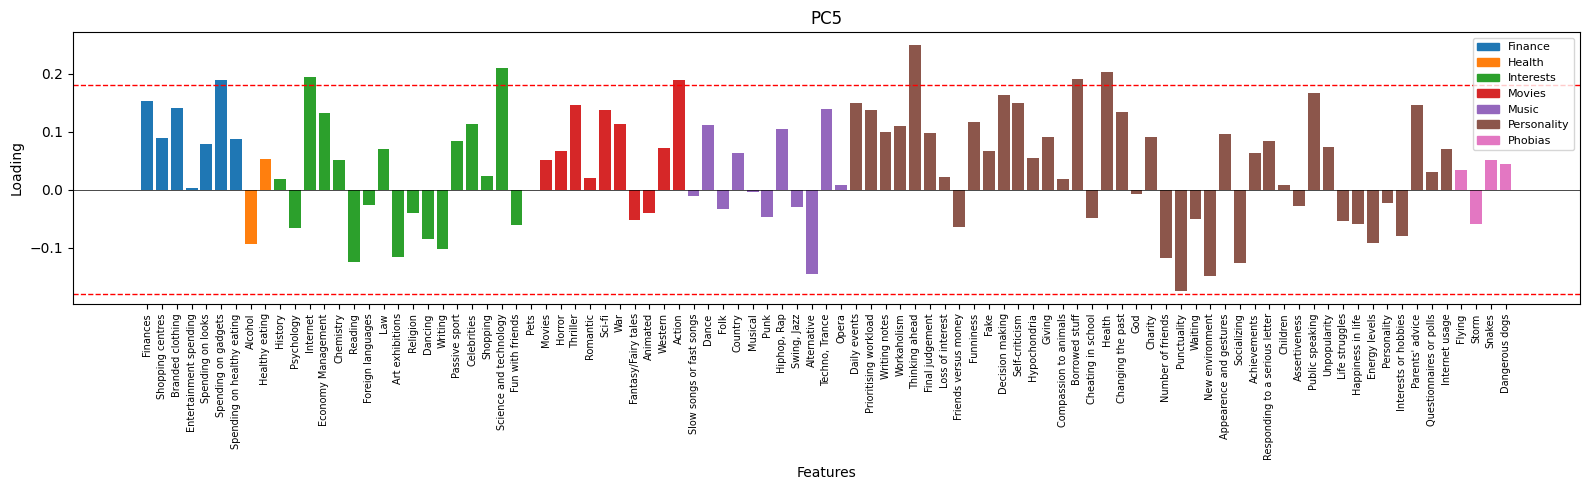

****************** PC5 **********************
HIGH-VALUED POSITIVE COMPONENTS: ['Spending on gadgets', 'Internet', 'Science and technology', 'Action', 'Thinking ahead', 'Borrowed stuff', 'Health']

HIGH-VALUED NEGATIVE COMPONENTS: []
*********************************************



In [10]:
# ============================================
# STEP 4: BARPLOT OF EACH PC (LOADINGS)
# ============================================

# Get loadings and feature names
loadings = pca_m.components_
feature_names = responses_ft_pp.columns.tolist()

# Threshold for "high-valued" components
threshold = 0.18

# Plot each PC
for i in range(m):
    pc_loadings = loadings[i]
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 5))
    
    # Bar plot colored by feature type
    ax.bar(range(len(pc_loadings)), pc_loadings, color=feature_colors)
    
    ax.set_xticks(range(len(feature_names)))
    ax.set_xticklabels(feature_names, rotation=90, fontsize=7)
    ax.set_xlabel('Features')
    ax.set_ylabel('Loading')
    ax.set_title(f'PC{i+1}')
    ax.axhline(y=0, color='black', linewidth=0.5)
    
    # Add threshold lines
    ax.axhline(y=threshold, color='red', linewidth=1, linestyle='--', label=f'Threshold (±{threshold})')
    ax.axhline(y=-threshold, color='red', linewidth=1, linestyle='--')
    
    # Add legend
    legend_handles = [plt.Rectangle((0,0),1,1, color=colors_by_type[t]) for t in colors_by_type]
    legend_labels = list(colors_by_type.keys())
    ax.legend(legend_handles, legend_labels, loc='upper right', fontsize=8)
    
    plt.tight_layout()
    plt.show()
    
    # Find high-valued components
    high_pos = [feature_names[j] for j in range(len(pc_loadings)) if pc_loadings[j] >= threshold]
    high_neg = [feature_names[j] for j in range(len(pc_loadings)) if pc_loadings[j] <= -threshold]
    
    print(f"{'*'*18} PC{i+1} {'*'*22}")
    print(f"HIGH-VALUED POSITIVE COMPONENTS: {high_pos}")
    print(f"")
    print(f"HIGH-VALUED NEGATIVE COMPONENTS: {high_neg}")
    print(f"{'*'*45}")
    print()

#### For each PC, write the name you assigned to it and a brief interpretation that motivate the choice (max 100 words per PC):

PC1 - "Romantic & Artistic Sensitivity (+)":
This component captures individuals with emotional and artistic tendencies. High positive loadings on Dancing, Shopping, Romantic movies, Fantasy/Fairy tales, and Musical reveal a preference for expressive and sentimental activities. The presence of Writing notes and Life struggles suggests emotionally aware individuals who reflect on their feelings. People scoring high on this PC tend to be sensitive, enjoy romantic and fantasy entertainment, and appreciate artistic expression. Since there are no significant negative loadings, this PC represents a one-sided dimension of emotional and romantic personality.

PC2 - "Social & Consumer Lifestyle (+)":
This component represents extroverted, socially active individuals with consumer-oriented behavior. High loadings on Branded clothing, Entertainment spending, Spending on looks, and Spending on gadgets indicate people who invest in their appearance and lifestyle. Features like Fun with friends, Number of friends, Socializing, and Energy levels reveal an outgoing personality who enjoys social gatherings. The presence of Hiphop/Rap and Interests or hobbies suggests engagement with popular culture. People scoring high are energetic, socially connected, and enjoy spending money on themselves and entertainment.

PC3 - "Intellectual & Cultural (-) vs Pop Culture (+)":
This component contrasts intellectual interests with mainstream pop culture. Positive loadings on History, Science and technology, and classical music genres (Country, Swing/Jazz, Opera, Alternative) represent individuals with cultural and academic curiosity. Negative loadings on Celebrities and Shopping indicate a rejection of superficial consumerism. People scoring positively tend to be intellectually curious, appreciate traditional or sophisticated music, and prefer depth over trends. Those scoring negatively are more interested in celebrity culture and shopping. This PC separates thoughtful individuals from trend-followers.

PC4 - "Melancholic & Reflective (-) vs Organized & Happy (+)":
This component captures a contrast between introspective dissatisfaction and positive life management. Positive loadings on Reading, Art exhibitions, and Alternative music appear alongside Loss of interest, Fake, and Changing the past - suggesting artistic individuals who struggle with regret and authenticity. Negative loadings on Prioritising workload, Happiness in life, and Energy levels represent organized, happy, and energetic people. High positive scorers may be creative but emotionally conflicted, while negative scorers are content, productive, and energetic. This PC separates melancholic reflectors from happy achievers.

PC5 - "Tech-Savvy & Practical (+)":
This component identifies technology-oriented, practical individuals. High loadings on Spending on gadgets, Internet, and Science and technology reveal tech enthusiasts. Action movies preference suggests a taste for dynamic entertainment. Thinking ahead, Borrowed stuff (responsibility with others' belongings), and Health indicate conscientious and forward-planning behavior. People scoring high on this PC are likely to be technologically engaged, health-conscious, and responsible. With no negative loadings, this represents a one-dimensional profile of modern, practical, technology-embracing individuals.

#### Write the code for visualizing the score graph (with PC names on the axis):

,Romantic & Artistic Sensitivity (+),Social & Consumer Lifestyle (+),Intellectual & Cultural (-) vs Pop Culture (+),Melancholic & Reflective (-) vs Organized & Happy (+),Tech-Savvy & Practical (+)
180,3.261312,0.905582,-0.526570,-1.814923,0.856430
233,-0.813490,0.799112,-1.734130,-0.596123,-0.032354
443,2.900850,1.300383,-0.899960,-2.136812,-0.580273
589,0.908759,-0.411745,-1.847202,-2.014581,-0.836534
468,1.590582,1.243736,0.267730,-0.451409,2.994464


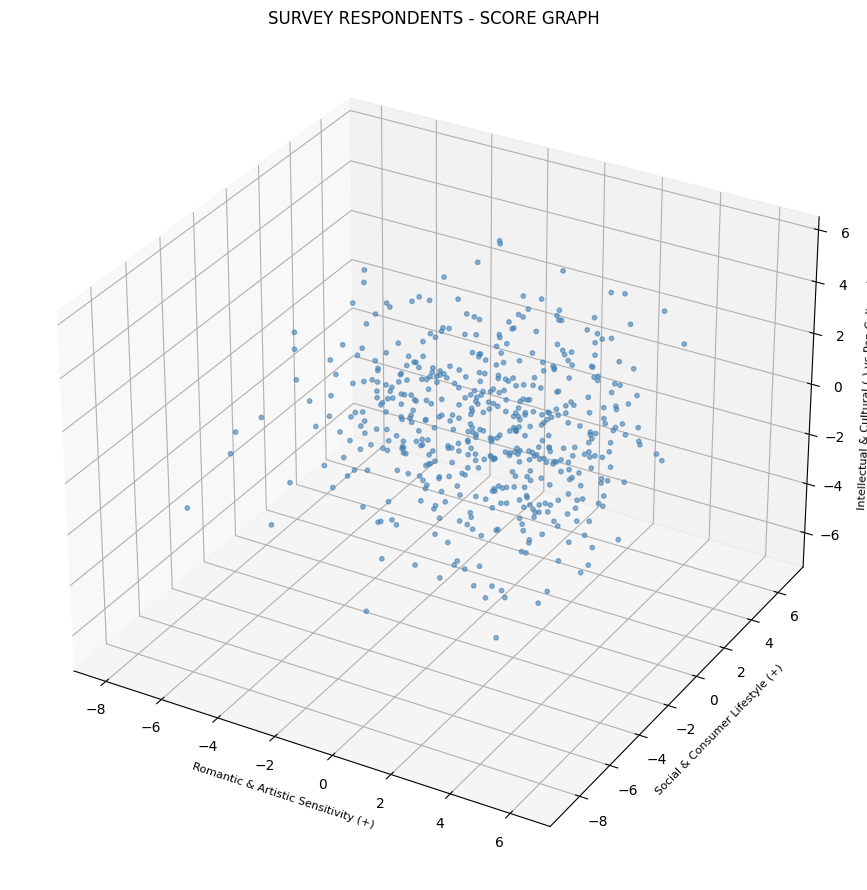

In [11]:
# ============================================
# STEP 5: DEFINE PC NAMES (based on interpretation)
# ============================================

pc_names = [
    'Romantic & Artistic Sensitivity (+)',
    'Social & Consumer Lifestyle (+)',
    'Intellectual & Cultural (-) vs Pop Culture (+)',
    'Melancholic & Reflective (-) vs Organized & Happy (+)',
    'Tech-Savvy & Practical (+)'
]

# ============================================
# STEP 6: TRANSFORM DATA
# ============================================

responses_ft_pca_values = pca_m.transform(responses_ft_pp)

responses_ft_pca = pd.DataFrame(
    responses_ft_pca_values,
    columns=pc_names,
    index=responses_ft_pp.index
)

display(responses_ft_pca.head(5))

# ============================================
# STEP 7: 3D SCORE GRAPH
# ============================================

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    responses_ft_pca.iloc[:, 0],  # PC1
    responses_ft_pca.iloc[:, 1],  # PC2
    responses_ft_pca.iloc[:, 2],  # PC3
    c='steelblue',
    alpha=0.6,
    s=10
)

ax.set_xlabel(pc_names[0], fontsize=8)
ax.set_ylabel(pc_names[1], fontsize=8)
ax.set_zlabel(pc_names[2], fontsize=8)
ax.set_title('SURVEY RESPONDENTS - SCORE GRAPH')

plt.tight_layout()
plt.show()

## Exercise 4. $k$-Means

In this exercise, you have to do the following operations:
1. Run the $k$-Means for clustering the data of *responses_ft_pca*, **setting the input argument *random_state* equal to the variable *random_seed*** (i.e., the minimum of the Student IDs).

   In particular, **use the silohuette score for identifying the best value for $k\in\{3, \ldots, 10\}$** and show it by plotting how the score changes w.r.t. $k$.
1. Plot the score graph again, but add the centroids of the cluster and color the points according to their cluster.
1. Visualize the centroids coordinates as barplots and **give a name and an interpretation to them by exploiting the PC names**.


#### Write the code for performing the items of the list above:

Computing silhouette scores for k = 3 to 10...
k = 3: Silhouette Score = 0.1711
k = 4: Silhouette Score = 0.1639
k = 5: Silhouette Score = 0.1443
k = 6: Silhouette Score = 0.1562
k = 7: Silhouette Score = 0.1536
k = 8: Silhouette Score = 0.1530
k = 9: Silhouette Score = 0.1474
k = 10: Silhouette Score = 0.1582


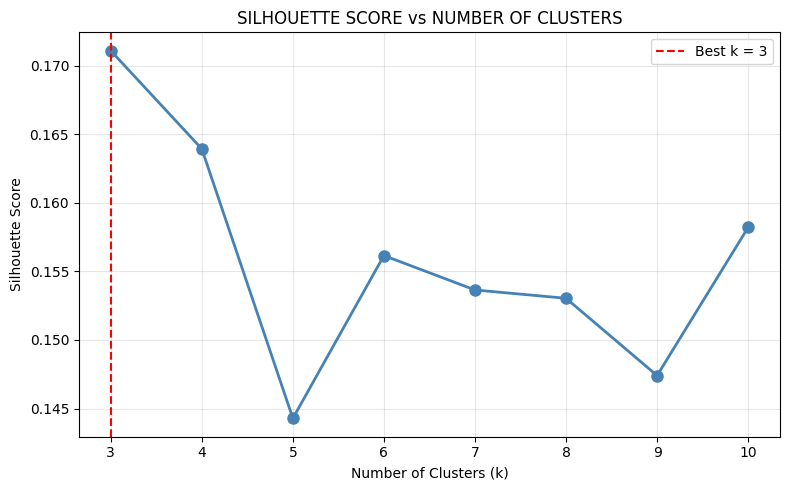


BEST k = 3 with Silhouette Score = 0.1711


In [12]:
# ============================================
# STEP 1: FIND BEST k USING SILHOUETTE SCORE
# ============================================

# Range of k values to try
k_range = range(3, 11) 

# Store silhouette scores
silhouette_scores = []

print("Computing silhouette scores for k = 3 to 10...")

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=random_seed, n_init=10)
    kmeans.fit(responses_ft_pca)
    labels = kmeans.labels_
    score = silhouette_score(responses_ft_pca, labels)
    silhouette_scores.append(score)
    print(f"k = {k}: Silhouette Score = {score:.4f}")

# Find best k
best_k = k_range[np.argmax(silhouette_scores)]
best_score = max(silhouette_scores)

# Plot silhouette scores
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_range, silhouette_scores, 'o-', color='steelblue', linewidth=2, markersize=8)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Silhouette Score')
ax.set_title('SILHOUETTE SCORE vs NUMBER OF CLUSTERS')
ax.set_xticks(k_range)
ax.grid(True, alpha=0.3)

# Mark the best k
ax.axvline(x=best_k, color='red', linestyle='--', label=f'Best k = {best_k}')
ax.legend()

plt.tight_layout()
plt.show()

print(f"\nBEST k = {best_k} with Silhouette Score = {best_score:.4f}")

In [13]:
# ============================================
# STEP 2: RUN k-MEANS WITH BEST k
# ============================================

kmeans_best = KMeans(n_clusters=best_k, random_state=random_seed, n_init=10)
kmeans_best.fit(responses_ft_pca)

# Get cluster labels and centroids
cluster_labels = kmeans_best.labels_
centroids = kmeans_best.cluster_centers_

# Calculate silhouette score
final_silhouette = silhouette_score(responses_ft_pca, cluster_labels)

# Show centroids
centroids_df = pd.DataFrame(centroids, columns=pc_names, index=[f'Cluster {i}' for i in range(best_k)])
display(centroids_df)

,Romantic & Artistic Sensitivity (+),Social & Consumer Lifestyle (+),Intellectual & Cultural (-) vs Pop Culture (+),Melancholic & Reflective (-) vs Organized & Happy (+),Tech-Savvy & Practical (+)
Cluster 0,1.922535,1.098471,-0.227205,-0.089280,-0.153831
Cluster 1,-2.660702,1.039558,0.097106,-0.129909,0.146565
Cluster 2,0.094218,-2.920043,0.241357,0.290096,0.069521


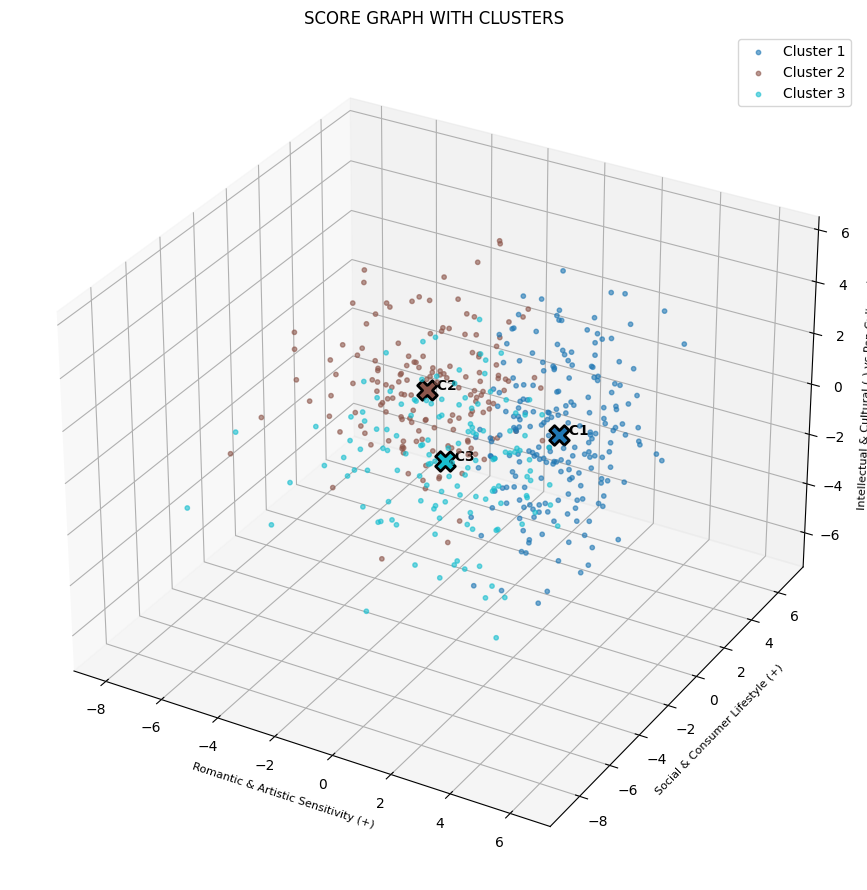

In [14]:
# ============================================
# STEP 3: 3D SCORE GRAPH WITH CLUSTERS
# ============================================

# Define colors for clusters
cluster_colors = plt.cm.tab10(np.linspace(0, 1, best_k))

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Plot each cluster with different color
for i in range(best_k):
    mask = cluster_labels == i
    ax.scatter(
        responses_ft_pca.iloc[mask, 0],
        responses_ft_pca.iloc[mask, 1],
        responses_ft_pca.iloc[mask, 2],
        c=[cluster_colors[i]],
        label=f'Cluster {i + 1}',
        alpha=0.6,
        s=10
    )

# Plot centroids (bigger markers)
for i in range(best_k):
    ax.scatter(
        centroids[i, 0],
        centroids[i, 1],
        centroids[i, 2],
        c=[cluster_colors[i]],
        marker='X',
        s=200,
        edgecolors='black',
        linewidths=2
    )
    ax.text(centroids[i, 0], centroids[i, 1], centroids[i, 2], f'  C{i + 1}', fontsize=10, fontweight='bold')

ax.set_xlabel(pc_names[0], fontsize=8)
ax.set_ylabel(pc_names[1], fontsize=8)
ax.set_zlabel(pc_names[2], fontsize=8)
ax.set_title('SCORE GRAPH WITH CLUSTERS')
ax.legend()

plt.tight_layout()
plt.show()

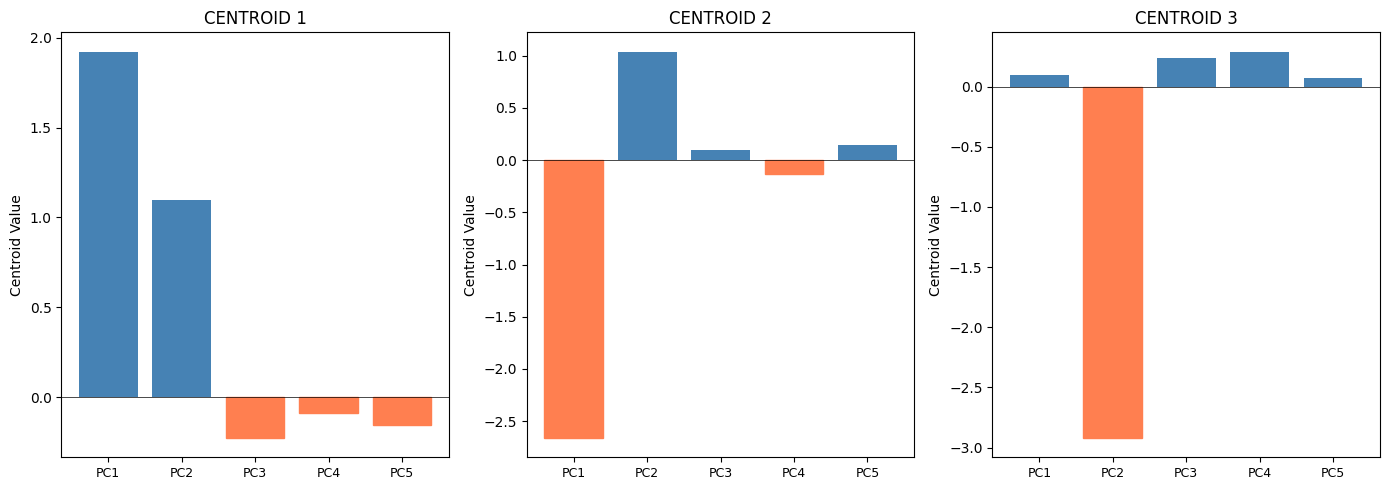

In [15]:
# ============================================
# STEP 4: CENTROID BARPLOTS
# ============================================

fig, axes = plt.subplots(1, best_k, figsize=(14, 5))

for i in range(best_k):
    ax = axes[i]
    bars = ax.bar(range(len(pc_names)), centroids[i], color='steelblue')
    
    # Color positive bars blue, negative bars coral
    for j, bar in enumerate(bars):
        if centroids[i, j] < 0:
            bar.set_color('coral')
    
    ax.set_xticks(range(len(pc_names)))
    ax.set_xticklabels([f'PC{j+1}' for j in range(len(pc_names))], fontsize=9)
    ax.set_ylabel('Centroid Value')
    ax.set_title(f'CENTROID {i+1}')
    ax.axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

#### For each Centroid, write the name you assigned to it and a brief interpretation that motivate the choice by exploiting the PC names(max 100 words per centroid):

Centroid 1 - "Social Romantics":
This cluster is characterized by high positive values on both PC1 (Romantic & Artistic Sensitivity) and PC2 (Social & Consumer Lifestyle). These individuals are emotionally expressive, enjoy romantic movies, fantasy, dancing, and artistic activities. They are also socially active, enjoy spending on appearance and entertainment, and have many friends. The combination suggests outgoing, emotionally open people who value both relationships and self-expression. They represent the most expressive and socially engaged group in the survey.

Centroid 2 - "Practical Socializers":
This cluster shows a very low PC1 (Romantic & Artistic) combined with high PC2 (Social & Consumer). These individuals are highly social and consumer-oriented - they enjoy spending, socializing, and maintaining an active lifestyle. However, they lack interest in romantic, artistic, or emotional activities. They are practical, outgoing people who prioritize social connections and material enjoyment over emotional or artistic expression. This profile suggests extroverted, pragmatic individuals focused on fun and social status.

Centroid 3 - "Independent Intellectuals":
This cluster is defined by a very low PC2 (Social & Consumer Lifestyle) while other PCs remain near neutral or slightly positive. These individuals are not driven by social activities, spending, or consumer behavior. The slightly positive PC3 (Intellectual) and PC4 (Happy/Organized) suggest they may be more intellectually curious and content with life. They represent introverted, self-sufficient individuals who prefer independence over social engagement and do not prioritize material consumption.

## Exercise 5. Cluster External Evaluations

In this exercise, you have to do the following operations:
1. Select a subset meaningful labels for performing an external evaluation of the clustering results.
1. For each selected label, visualize the distribution of the label in each cluster and in the whole dataset.
1. Visualize the score graph with dots colored with respect to the label value; then, visualize the clusters in separated score-graphs, coloring the points according to the label values.


#### List the Labels you consider meaningful for an external cluster evaluation and motivate your choice (max 50 words per label):

Gender:
Gender may influence clustering results as romantic/artistic sensitivity (PC1) and social behavior (PC2) often show differences between males and females. Analyzing gender distribution across clusters helps verify if our clustering captures gender-related behavioral patterns.

Education:
Education level could relate to intellectual curiosity (PC3) and lifestyle choices. Higher education may correlate with the Independent Intellectuals cluster, while different education levels might show different social and consumer patterns.

Home Town Type (City vs Village):
Urban versus rural background may influence social and consumer behavior (PC2). City residents might show higher consumer tendencies and social activities, while village residents may display different lifestyle patterns captured by our clusters.


#### Write the code for the visualizations cited in item 2 above:

In [18]:
# ============================================
# STEP 1: SHOW AVAILABLE LABELS
# ============================================

print("*** AVAILABLE LABELS FOR EXTERNAL EVALUATION:")
print(responses_lb.columns.tolist())

selected_labels = ['Gender']

*** AVAILABLE LABELS FOR EXTERNAL EVALUATION:
['Age', 'Height', 'Weight', 'Number of siblings', 'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type', 'Home Type']



*** DISTRIBUTION OF 'Gender' ***

--- Overall Distribution ---
Gender
female    292
male      214
Name: count, dtype: int64

--- Cluster 1 ---
Gender
female    173
male       39
Name: count, dtype: int64

--- Cluster 2 ---
Gender
male      135
female     23
Name: count, dtype: int64

--- Cluster 3 ---
Gender
female    96
male      40
Name: count, dtype: int64


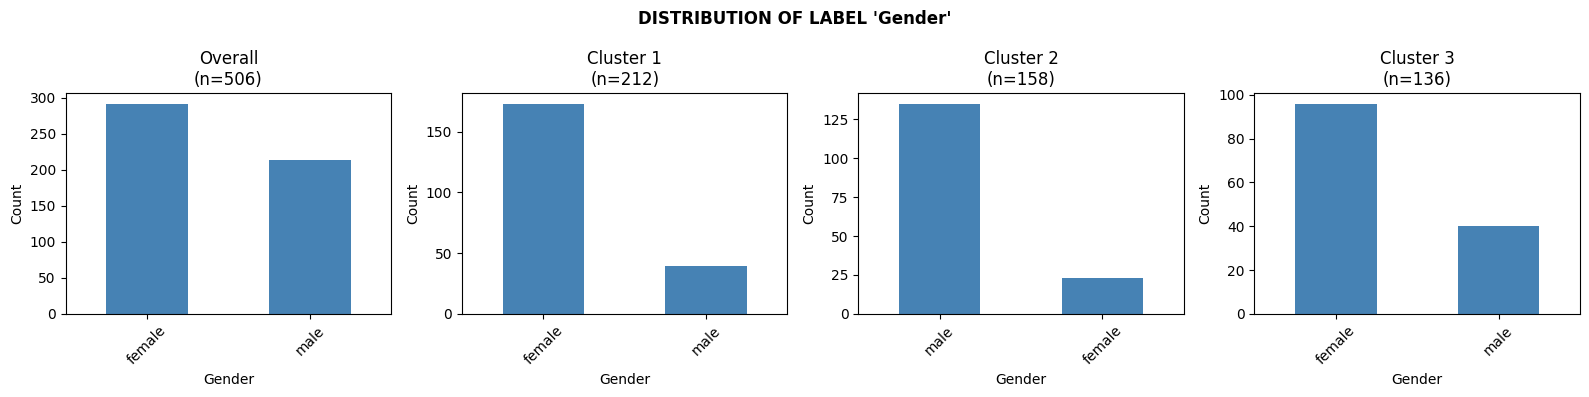

In [19]:
# ============================================
# STEP 2: DISTRIBUTION OF LABELS IN EACH CLUSTER
# ============================================

# Add cluster labels to responses_lb for analysis
responses_lb_with_clusters = responses_lb.copy()
responses_lb_with_clusters['Cluster'] = cluster_labels + 1 

# For each selected label, show distribution
for label in selected_labels:
    
    print(f"\n{'='*50}")
    print(f"*** DISTRIBUTION OF '{label}' ***")
    print(f"{'='*50}")
    
    # Overall distribution
    print(f"\n--- Overall Distribution ---")
    print(responses_lb[label].value_counts())
    
    # Distribution per cluster
    for c in range(1, best_k + 1):
        cluster_data = responses_lb_with_clusters[responses_lb_with_clusters['Cluster'] == c]
        print(f"\n--- Cluster {c} ---")
        print(cluster_data[label].value_counts())
    
    # Visualization: bar plot for each cluster + overall
    fig, axes = plt.subplots(1, best_k + 1, figsize=(16, 4))
    
    # Overall
    responses_lb[label].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
    axes[0].set_title(f'Overall\n(n={len(responses_lb)})')
    axes[0].set_xlabel(label)
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=45)
    
    # Per cluster
    for c in range(1, best_k + 1):
        cluster_data = responses_lb_with_clusters[responses_lb_with_clusters['Cluster'] == c]
        cluster_data[label].value_counts().plot(kind='bar', ax=axes[c], color='steelblue')
        axes[c].set_title(f'Cluster {c}\n(n={len(cluster_data)})')
        axes[c].set_xlabel(label)
        axes[c].set_ylabel('Count')
        axes[c].tick_params(axis='x', rotation=45)
    
    plt.suptitle(f"DISTRIBUTION OF LABEL '{label}'", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

#### For each selected label, comment the results observed in the visualizations (max 100 words per label):

Gender: 
The clustering shows strong gender differentiation. Cluster 1 (Social Romantics) contains 82% females, aligning with higher romantic and artistic sensitivity. Cluster 2 (Practical Socializers) contains 85% males, showing social behavior without romantic tendencies. Cluster 3 is mixed with 71% females. This validates our clustering - the algorithm discovered gender-related behavioral patterns without using gender as input.

Education: 
Education shows moderate variation across clusters but no strong pattern. All clusters contain similar proportions of secondary school and college students, suggesting education level doesn't strongly determine personality-based clustering in this young population.

Home Town Type: 
City/village distribution is relatively balanced across clusters, indicating that urban versus rural background doesn't strongly influence the personality and interest patterns captured by our PCA and clustering.

## Exercise 6. Cluster Internal Evaluations

In this exercise, you have to do the following operations:
1. For each cluster, measure the corresponding average silhouette score
1. Visualize the silhouette of the clusters and the general one of the clustering and compare them


#### Write the code for computing the silhouette scores and for visualizing them:

*** SILHOUETTE SCORES PER CLUSTER ***

Cluster 1: 0.1917
Cluster 2: 0.1736
Cluster 3: 0.1360

Global: 0.1711


,Sil. Score
Cluster 1,0.191652
Cluster 2,0.173644
Cluster 3,0.136032
Global,0.171080


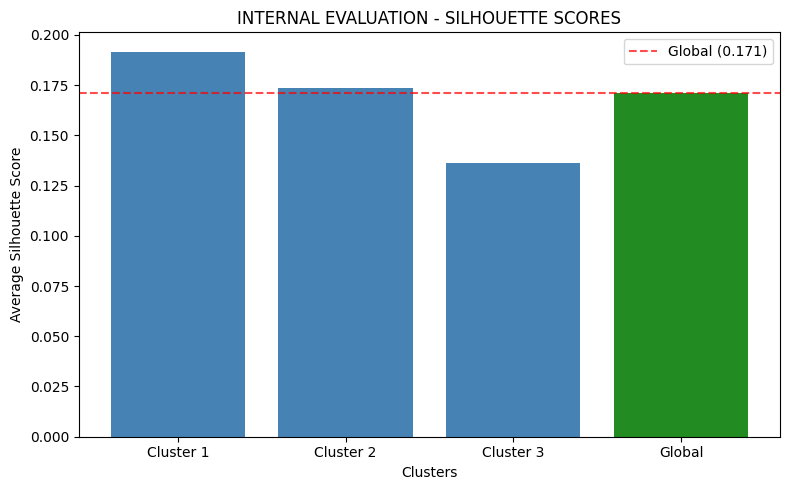

In [20]:
# ============================================
# EXERCISE 6: INTERNAL EVALUATION - SILHOUETTE
# ============================================

# Get silhouette score for each sample
silhouette_vals = silhouette_samples(responses_ft_pca, cluster_labels)

# Calculate average silhouette for each cluster
cluster_names = ['Cluster 1\nSocial Romantics', 'Cluster 2\nPractical Socializers', 'Cluster 3\nIndependent Intellectuals']
silhouette_per_cluster = []

print("*** SILHOUETTE SCORES PER CLUSTER ***\n")
for i in range(best_k):
    cluster_silhouette = silhouette_vals[cluster_labels == i].mean()
    silhouette_per_cluster.append(cluster_silhouette)
    print(f"Cluster {i+1}: {cluster_silhouette:.4f}")

# Global silhouette (already calculated in Exercise 4)
global_silhouette = silhouette_score(responses_ft_pca, cluster_labels)
print(f"\nGlobal: {global_silhouette:.4f}")

# Create DataFrame for display
silhouette_df = pd.DataFrame({
    'Sil. Score': silhouette_per_cluster + [global_silhouette]
}, index=[f'Cluster {i+1}' for i in range(best_k)] + ['Global'])
display(silhouette_df)

# ============================================
# VISUALIZATION
# ============================================

fig, ax = plt.subplots(figsize=(8, 5))

# Bar plot
x_labels = [f'Cluster {i+1}' for i in range(best_k)] + ['Global']
values = silhouette_per_cluster + [global_silhouette]
colors = ['steelblue'] * best_k + ['forestgreen']

bars = ax.bar(x_labels, values, color=colors)

ax.set_ylabel('Average Silhouette Score')
ax.set_xlabel('Clusters')
ax.set_title('INTERNAL EVALUATION - SILHOUETTE SCORES')
ax.axhline(y=global_silhouette, color='red', linestyle='--', alpha=0.7, label=f'Global ({global_silhouette:.3f})')
ax.legend()

plt.tight_layout()
plt.show()

#### Comment the results, also considering the results observed previously (e.g., score graphs, centroids, etc. - max 150 words):

The silhouette scores reveal varying cluster quality. Cluster 1 (Social Romantics) has the highest score (0.192), indicating its members are most distinctly grouped - this aligns with the strong gender differentiation (82% female) observed in Exercise 5. Cluster 2 (Practical Socializers) scores 0.174, showing moderate cohesion. Cluster 3 (Independent Intellectuals) has the lowest score (0.136), suggesting more overlap with other clusters, likely because these individuals are defined more by what they lack (low social/consumer behavior) than distinct positive traits.